# TextCNN notebook (CSCI167 Rotten Tomatoes project)

This is a copy of the shared model template with a 1D CNN (TextCNN) as the architecture.

Everything in here is **shared code that all of us use**: setup, data and splits, the common training settings,
the run function, the results table, learning curves and error analysis. Do not edit `common.py` or the shared
settings, so that all models are trained and evaluated the same way and the results are comparable.
The only part you write is the architecture, in the cell(s) under **YOUR ARCHITECTURE**.

Colab: Runtime > Change runtime type > GPU (T4), then run cells top to bottom.

In [ ]:
%pip install -q datasets transformers
import os
if not os.path.exists("common.py"):
    REPO_URL = "https://github.com/ZhongVang/csci167-rotten-tomatoes.git"   # group repo (private until submission)
    !git clone $REPO_URL project
    %cd project

In [ ]:
# Optional (Colab): keep results on Drive so they survive session timeouts.
# Must run BEFORE `import common`.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ["RESULTS_DIR"] = "/content/drive/MyDrive/CSCI167_results"
except Exception:
    pass  # running locally: results go to ./results

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
OWNER = "Mathan"                   # TODO: your name; results go to results_<OWNER>.csv
RESULTS_FILE = f"results_{OWNER}.csv"
SEEDS = [0, 1, 2]                    # shared: do not change

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from common import *

print(save_env_info(OWNER))          # package versions + hardware, for the report
data = load_data()
print({k: len(v[0]) for k, v in data.items()}, "-> train/val/test sizes")
print("label counts (train):", np.bincount(data["train"][1]))
print("example:", data["train"][0][0], "->", data["train"][1][0])

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'cuda': '13.0', 'gpu': 'Tesla T4', 'common_version': '65ca4193', 'datasets': '4.8.5', 'transformers': '5.22.1', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'dataset_revision': 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28', 'dataset_id': 'cornell-movie-review-data/rotten_tomatoes'}
{'train': 8530, 'validation': 1066, 'test': 1066} -> train/val/test sizes
label counts (train): [4265 4265]
example: the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal . -> 1


## Shared training settings (do not change for the main runs)

Every model in the group is trained with the same budget so the comparison is fair: Adam, lr 1e-3, batch 64,
at most 20 epochs, early stopping (patience 5) on **validation** accuracy; the best-validation weights are
restored and the test set is evaluated once at the end. The same 3 seeds are used for 100%, 25% and 10% of the
training data. Data: official splits of `cornell-movie-review-data/rotten_tomatoes`
(train 8,530 / validation 1,066 / test 1,066).

In [ ]:
TAG = "cnn"               # TODO: short unique name used in run names / files (e.g. "cnn")
MODEL_NAME = "TextCNN (scratch)"       # TODO: descriptive name shown in the results table

PROTOCOL = dict(optimizer="adam", lr=1e-3, batch_size=64, epochs=20, patience=5)
FRACS = [1.0, 0.25, 0.1]

def run(seed, frac, tag=None, **overrides):
    """Train + evaluate one run and log it to results/<RESULTS_FILE>.
    overrides: training settings (optimizer, lr, weight_decay, schedule, momentum) go to the trainer;
    anything else is passed to MyModel(...) as a model hyperparameter (e.g. dropout=0.0)."""
    train_keys = {"optimizer", "lr", "weight_decay", "schedule", "momentum"}
    tcfg = {**PROTOCOL, **{k: v for k, v in overrides.items() if k in train_keys}}
    mcfg = {k: v for k, v in overrides.items() if k not in train_keys}
    set_seed(seed)                                    # BEFORE building the model
    train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, tcfg["batch_size"], seed, train_frac=frac)
    model = MyModel(len(vocab), **mcfg)
    return train_and_eval(model, (train_dl, val_dl, test_dl), run_name=f"{tag or TAG}_f{frac}_s{seed}",
                          model_name=MODEL_NAME, seed=seed, train_frac=frac, extra=mcfg,
                          results_file=RESULTS_FILE, **tcfg)

## YOUR ARCHITECTURE: TextCNN

I used a 1D convolutional network from Chapter 10.2 (convolutional networks for 1D inputs). It uses a 128-dimensional word embedding and three parallel 1D convolutions with kernel sizes 3, 4, and 5 (100 filters each). The network then uses ReLU, max-over-time pooling, a dropout of 0.5, and a linear layer for the two classes (0 = negative, 1 = positive).

Each filter works as an n-gram detector over a window of 3-5 words, with the max-over-time pooling keeping the strongest match from the sentence. Padded positions are masked out of the pooling, and short batches are padded so the widest kernel fits. Everything is then trained from scratch, with nothing being pretrained or frozen. The trainable parameter count is printed in the sanity check below.

I chose CNN because the sentiment in short sentences is carried by short phrases, and a CNN is fast to train with few parameters outside of the embedding table.

In [ ]:
class MyModel(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, n_filters=100, kernels=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.kernels = tuple(kernels)
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k) for k in self.kernels])
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(n_filters * len(self.kernels), 2)

    def forward(self, ids, mask):
        x = self.emb(ids)                                   # [B, T, E]
        mask = mask.long()
        K = max(self.kernels)
        if x.size(1) < K:                                   # batch shorter than widest kernel
            extra = K - x.size(1)
            x = F.pad(x, (0, 0, 0, extra))
            mask = F.pad(mask, (0, extra))
        x = x.transpose(1, 2)                               # [B, E, T]
        lengths = mask.sum(1)
        feats = []
        for conv, k in zip(self.convs, self.kernels):
            h = torch.relu(conv(x))                         # [B, F, T-k+1]
            pos = torch.arange(h.size(2), device=h.device).unsqueeze(0)
            valid = (pos + k) <= lengths.clamp(min=k).unsqueeze(1)
            h = h.masked_fill(~valid.unsqueeze(1), 0.0)
            feats.append(h.max(dim=2).values)               # max-over-time pooling
        return self.head(self.drop(torch.cat(feats, dim=1)))   # [B, 2]

## Sanity check (run once your model is defined)

Builds your model, prints its structure and trainable parameter count (needed for the report), and checks
the output shape on a real batch. Then run one short test (10% of the data) before the full runs.

In [ ]:
set_seed(0)
train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, 64, 0)
model = MyModel(len(vocab))
print(model)
print("trainable / total params:", count_params(model))
inputs, y = next(iter(train_dl))
out = model(**inputs)
assert out.shape == (len(y), 2), f"forward() must return logits of shape [batch, 2], got {tuple(out.shape)}"
print("OK: logits", tuple(out.shape), "| ids", tuple(inputs['ids'].shape))

MyModel(
  (emb): Embedding(8981, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(128, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(128, 100, kernel_size=(5,), stride=(1,))
  )
  (drop): Dropout(p=0.5, inplace=False)
  (head): Linear(in_features=300, out_features=2, bias=True)
)
trainable / total params: (1304070, 1304070)
OK: logits (64, 2) | ids (64, 46)


In [ ]:
run(0, 0.1, tag=TAG + '_test')   # quick test: if validation accuracy is above 50%, launch the full runs

[cnn_test_f0.1_s0] ep 01 train_loss 0.8131 train_acc 0.5188 val_loss 0.7229 val_acc 0.5075
[cnn_test_f0.1_s0] ep 02 train_loss 0.6445 train_acc 0.6408 val_loss 0.6836 val_acc 0.5750
[cnn_test_f0.1_s0] ep 03 train_loss 0.5209 train_acc 0.7477 val_loss 0.6891 val_acc 0.5863
[cnn_test_f0.1_s0] ep 04 train_loss 0.4432 train_acc 0.8181 val_loss 0.6737 val_acc 0.5976
[cnn_test_f0.1_s0] ep 05 train_loss 0.3602 train_acc 0.8826 val_loss 0.6811 val_acc 0.5901
[cnn_test_f0.1_s0] ep 06 train_loss 0.2928 train_acc 0.9261 val_loss 0.6905 val_acc 0.5675
[cnn_test_f0.1_s0] ep 07 train_loss 0.2651 train_acc 0.9272 val_loss 0.6961 val_acc 0.5704
[cnn_test_f0.1_s0] ep 08 train_loss 0.2108 train_acc 0.9495 val_loss 0.7022 val_acc 0.5882
[cnn_test_f0.1_s0] ep 09 train_loss 0.1499 train_acc 0.9707 val_loss 0.7155 val_acc 0.5919
[cnn_test_f0.1_s0] early stop at epoch 9
[cnn_test_f0.1_s0] best_val 0.5976 (ep 4) | TEST acc 0.6023 f1 0.6018 | 3s | trainable params 346,374


{'timestamp': '2026-11-26T03:18:56',
 'run_name': 'cnn_test_f0.1_s0',
 'model': 'TextCNN (scratch)',
 'seed': 0,
 'train_frac': 0.1,
 'n_train': 852,
 'n_val': 1066,
 'n_test': 1066,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'schedule': 'constant',
 'batch_size': 64,
 'epochs_max': 20,
 'patience': 5,
 'epochs_run': 9,
 'best_epoch': 4,
 'best_val_acc': 0.5976,
 'test_acc': 0.6023,
 'test_f1': 0.6018,
 'trainable_params': 346374,
 'total_params': 346374,
 'train_seconds': 2.9,
 'device': 'cuda',
 'common_version': '65ca4193',
 'extra': '{}'}

[cnn_test_f0.1_s0] ep 01 train_loss 0.8131 train_acc 0.5188 val_loss 0.7229 val_acc 0.5075
[cnn_test_f0.1_s0] ep 02 train_loss 0.6445 train_acc 0.6408 val_loss 0.6836 val_acc 0.5750
[cnn_test_f0.1_s0] ep 03 train_loss 0.5209 train_acc 0.7477 val_loss 0.6891 val_acc 0.5863
[cnn_test_f0.1_s0] ep 04 train_loss 0.4432 train_acc 0.8181 val_loss 0.6737 val_acc 0.5976
[cnn_test_f0.1_s0] ep 05 train_loss 0.3602 train_acc 0.8826 val_loss 0.6811 val_acc 0.5901
[cnn_test_f0.1_s0] ep 06 train_loss 0.2928 train_acc 0.9261 val_loss 0.6905 val_acc 0.5675
[cnn_test_f0.1_s0] ep 07 train_loss 0.2651 train_acc 0.9272 val_loss 0.6961 val_acc 0.5704
[cnn_test_f0.1_s0] ep 08 train_loss 0.2108 train_acc 0.9495 val_loss 0.7022 val_acc 0.5882
[cnn_test_f0.1_s0] ep 09 train_loss 0.1499 train_acc 0.9707 val_loss 0.7155 val_acc 0.5919
[cnn_test_f0.1_s0] early stop at epoch 9
[cnn_test_f0.1_s0] best_val 0.5976 (ep 4) | TEST acc 0.6023 f1 0.6018 | 2s | trainable params 346,374


{'timestamp': '2026-11-26T03:21:30',
 'run_name': 'cnn_test_f0.1_s0',
 'model': 'TextCNN (scratch)',
 'seed': 0,
 'train_frac': 0.1,
 'n_train': 852,
 'n_val': 1066,
 'n_test': 1066,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'schedule': 'constant',
 'batch_size': 64,
 'epochs_max': 20,
 'patience': 5,
 'epochs_run': 9,
 'best_epoch': 4,
 'best_val_acc': 0.5976,
 'test_acc': 0.6023,
 'test_f1': 0.6018,
 'trainable_params': 346374,
 'total_params': 346374,
 'train_seconds': 1.6,
 'device': 'cuda',
 'common_version': '65ca4193',
 'extra': '{}'}

In [ ]:
os.remove(f"{RESULTS_DIR}/{RESULTS_FILE}")

## Main runs: 3 seeds x 100% / 25% / 10% of the training data

In [ ]:
for frac in FRACS:
    for seed in SEEDS:
        run(seed, frac)

[cnn_f1.0_s0] ep 01 train_loss 0.7162 train_acc 0.5529 val_loss 0.6507 val_acc 0.6248
[cnn_f1.0_s0] ep 02 train_loss 0.6025 train_acc 0.6742 val_loss 0.6274 val_acc 0.6473
[cnn_f1.0_s0] ep 03 train_loss 0.5346 train_acc 0.7370 val_loss 0.6304 val_acc 0.6501
[cnn_f1.0_s0] ep 04 train_loss 0.4368 train_acc 0.8007 val_loss 0.6091 val_acc 0.6726
[cnn_f1.0_s0] ep 05 train_loss 0.3481 train_acc 0.8478 val_loss 0.6256 val_acc 0.6932
[cnn_f1.0_s0] ep 06 train_loss 0.2723 train_acc 0.8878 val_loss 0.6594 val_acc 0.7129
[cnn_f1.0_s0] ep 07 train_loss 0.2128 train_acc 0.9137 val_loss 0.7162 val_acc 0.7017
[cnn_f1.0_s0] ep 08 train_loss 0.1646 train_acc 0.9372 val_loss 0.7405 val_acc 0.7054
[cnn_f1.0_s0] ep 09 train_loss 0.1256 train_acc 0.9553 val_loss 0.8123 val_acc 0.7008
[cnn_f1.0_s0] ep 10 train_loss 0.0979 train_acc 0.9658 val_loss 0.8563 val_acc 0.7205
[cnn_f1.0_s0] ep 11 train_loss 0.0810 train_acc 0.9717 val_loss 0.9057 val_acc 0.7158
[cnn_f1.0_s0] ep 12 train_loss 0.0656 train_acc 0.9803

## Results: summary table, learning curves, error analysis

In [ ]:
summarize(f'results_{OWNER}.csv')   # mean +/- std over seeds, per configuration

,model,train_frac,optimizer,lr,weight_decay,schedule,batch_size,extra,n_seeds,val_acc,val_std,test_acc,test_std,test_f1,params,seconds
0,TextCNN (scratch),0.10,adam,0.001,0.0,constant,64,{},3,0.6007,0.0027,0.5966,0.0114,0.5932,346374,2.1667
1,TextCNN (scratch),0.25,adam,0.001,0.0,constant,64,{},3,0.6307,0.0128,0.6420,0.0024,0.6414,582790,3.3000
2,TextCNN (scratch),1.00,adam,0.001,0.0,constant,64,{},3,0.7248,0.0060,0.7295,0.0235,0.7292,1304070,13.3667


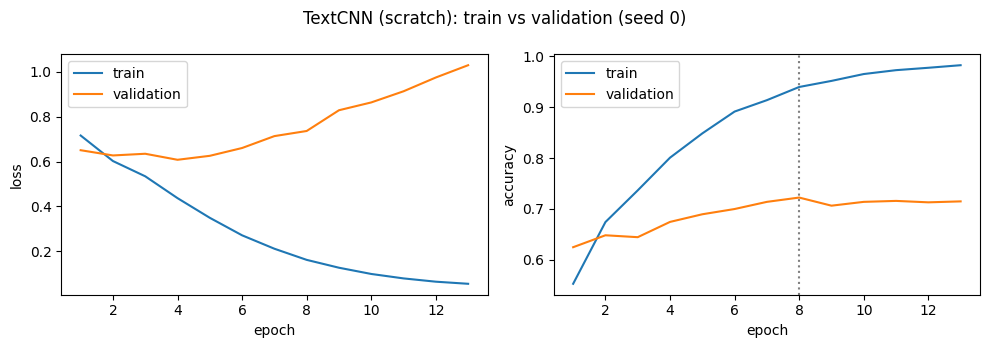

In [ ]:
plot_history(f"{TAG}_f1.0_s0", f"{MODEL_NAME}: train vs validation (seed 0)");

In [ ]:
import json
h = json.load(open(f"{RESULTS_DIR}/history/{TAG}_f1.0_s0.json"))
preds, labels = np.array(h["test_preds"]), np.array(data["test"][1])
texts = data["test"][0]
cm = np.zeros((2, 2), int)
for y, p in zip(labels, preds): cm[y, p] += 1
print("confusion matrix (rows=true neg/pos, cols=pred neg/pos):\n", cm)
wrong = np.where(preds != labels)[0]
print(len(wrong), "errors. Examples (true, pred, text):")
rng = np.random.default_rng(0)
for i in rng.choice(wrong, 20, replace=False): print(labels[i], preds[i], "|", texts[i])

confusion matrix (rows=true neg/pos, cols=pred neg/pos):
 [[377 156]
 [133 400]]
289 errors. Examples (true, pred, text):
0 1 | one key problem with these ardently christian storylines is that there is never any question of how things will turn out .
1 0 | this seductive tease of a thriller gets the job done . it's a scorcher .
1 0 | oh , james ! your 20th outing shows off a lot of stamina and vitality , and get this , madonna's cameo doesn't suck !
0 1 | though it was made with careful attention to detail and is well-acted by james spader and maggie gyllenhaal , i felt disrespected .
0 1 | allegiance to chekhov , which director michael cacoyannis displays with somber earnestness in the new adaptation of the cherry orchard , is a particularly vexing handicap .
0 1 | my advice is to skip the film and pick up the soundtrack .
0 1 | according to wendigo , 'nature' loves the members of the upper class almost as much as they love themselves .
0 1 | the plot is paper-thin and the characters 

In [ ]:
vocab = make_vocab_loaders(data, 64, 0)[3]
unk = lambda t: np.mean([w not in vocab for w in t.split()])
right = np.where(preds == labels)[0]
print("unknown-word rate in errors :", np.mean([unk(texts[i]) for i in wrong]))
print("unknown-word rate in correct:", np.mean([unk(texts[i]) for i in right]))

unknown-word rate in errors : 0.09671262728663922
unknown-word rate in correct: 0.08250596222634092
unknown-word rate in errors : 0.09326837980515301
unknown-word rate in correct: 0.08354933529759657


## Kernel-size ablation (TextCNN, full training set, 3 seeds)

**Search strategy:** one factor at a time against the reference (Adam, lr 1e-3, dropout 0.5, kernels (3, 4, 5), max 20 epochs, early stopping on validation accuracy). Kernel sizes: (3,), (3, 4, 5) (reference) and (2, 3, 4, 5). Settings were compared on validation accuracy only.

**Results:** Validation accuracy was 73.1% for (3,), 72.5% for (3, 4, 5) and 73.4% for (2, 3, 4, 5). The best setting by validation was (2, 3, 4, 5), but the differences are under 1 point, which is about the size of the seed-to-seed standard deviation (0.2-0.8 points), so there is no clear winner. The single-kernel model has the fewest parameters (1.19M, versus 1.30M and 1.33M) and its best epoch comes latest (about 15, versus 12 and 13), while training time was similar (11-15 s per run).

**Caveats:** only 3 seeds and a validation set of 1,066 sentences, so differences under about 1 point are unreliable. This is one architectural factor, not the group's hyperparameter study, which was run on the transformer. The main results table uses the shared default kernels (3, 4, 5).

In [ ]:
for seed in SEEDS:
    run(seed, 1.0, tag=TAG + "_k3", kernels=(3,))
    run(seed, 1.0, tag=TAG + "_k2345", kernels=(2, 3, 4, 5))

[cnn_k3_f1.0_s0] ep 01 train_loss 0.7206 train_acc 0.5469 val_loss 0.6625 val_acc 0.6069
[cnn_k3_f1.0_s0] ep 02 train_loss 0.6441 train_acc 0.6247 val_loss 0.6372 val_acc 0.6463
[cnn_k3_f1.0_s0] ep 03 train_loss 0.6010 train_acc 0.6778 val_loss 0.6142 val_acc 0.6492
[cnn_k3_f1.0_s0] ep 04 train_loss 0.5346 train_acc 0.7321 val_loss 0.5941 val_acc 0.6689
[cnn_k3_f1.0_s0] ep 05 train_loss 0.4820 train_acc 0.7706 val_loss 0.6041 val_acc 0.6904
[cnn_k3_f1.0_s0] ep 06 train_loss 0.4171 train_acc 0.8087 val_loss 0.5867 val_acc 0.6998
[cnn_k3_f1.0_s0] ep 07 train_loss 0.3634 train_acc 0.8430 val_loss 0.5920 val_acc 0.7111
[cnn_k3_f1.0_s0] ep 08 train_loss 0.3099 train_acc 0.8669 val_loss 0.6079 val_acc 0.7101
[cnn_k3_f1.0_s0] ep 09 train_loss 0.2603 train_acc 0.8934 val_loss 0.6350 val_acc 0.7083
[cnn_k3_f1.0_s0] ep 10 train_loss 0.2115 train_acc 0.9149 val_loss 0.6709 val_acc 0.7036
[cnn_k3_f1.0_s0] ep 11 train_loss 0.1745 train_acc 0.9355 val_loss 0.7142 val_acc 0.7167
[cnn_k3_f1.0_s0] ep 1

In [ ]:
import pandas as pd
df = pd.read_csv(f"{RESULTS_DIR}/{RESULTS_FILE}")
df = df[df.train_frac == 1.0].copy()
df["kernels"] = df["extra"].apply(lambda s: json.loads(s).get("kernels", [3, 4, 5]))
df["kernels"] = df["kernels"].apply(lambda k: str(tuple(k)))
print(df.groupby("kernels").agg(
    n_seeds=("seed", "nunique"),
    val_acc=("best_val_acc", "mean"), val_std=("best_val_acc", "std"),
    test_acc=("test_acc", "mean"), test_std=("test_acc", "std"),
    best_epoch=("best_epoch", "mean"), params=("trainable_params", "mean"),
    seconds=("train_seconds", "mean")).round(4))

              n_seeds  val_acc  val_std  test_acc  test_std  best_epoch  \
kernels                                                                   
(2, 3, 4, 5)        3   0.7305   0.0081    0.7370    0.0134     10.6667   
(3, 4, 5)           3   0.7245   0.0035    0.7355    0.0185      9.6667   
(3,)                3   0.7326   0.0043    0.7414    0.0160     16.3333   

                 params  seconds  
kernels                           
(2, 3, 4, 5)  1329970.0  13.4333  
(3, 4, 5)     1304070.0  11.4667  
(3,)          1188270.0  11.9333  
              n_seeds  val_acc  val_std  test_acc  test_std  best_epoch  \
kernels                                                                   
(2, 3, 4, 5)        3   0.7336   0.0084    0.7323    0.0120     13.0000   
(3, 4, 5)           3   0.7248   0.0060    0.7295    0.0235     11.6667   
(3,)                3   0.7314   0.0020    0.7464    0.0135     15.3333   

                 params  seconds  
kernels                           
(2,

## Notes for the report

- **Design choices:** I used a 1D convolutional network from Chapter 10.2 (convolutional networks for 1D inputs). It uses a 128-dimensional word embedding and three parallel 1D convolutions with kernel sizes 3, 4, and 5 (100 filters each), followed by ReLU, max-over-time pooling over the non-padding words, dropout 0.5, and a linear layer for the two classes (0 = negative, 1 = positive). It has 1,304,070 trainable parameters at 100% training data; the embedding table accounts for 1,149,568 of them (8,981 x 128, about 88%), and the convolutions account for about 154k. The vocabulary is built from the training text only, so the parameter count is smaller at 25% (about 580k) and 10% (about 347k) of the data, and it varies slightly by seed because each seed draws a different subset. I expected it to do well when the sentiment is carried by a short phrase and worse when it depends on structure across the whole sentence. Everything is trained from scratch; nothing is pretrained or frozen.
- **Learning curves:** The model overfits. On seed 0, training accuracy reaches about 98% by epoch 13 while validation accuracy peaks at 72.2% (epoch 8). Validation loss is lowest at epoch 4 (0.61) and then rises to about 1.03 at epoch 13, while training loss keeps falling to about 0.06, although validation accuracy keeps improving until epoch 8. Early stopping on validation accuracy selected epochs 8, 15, and 12 for seeds 0, 1, and 2 at 100% of the data. In Zhong's transformer run, validation loss climbed higher (about 1.6-2.0), so the CNN overfits more slowly.
- **Errors:** On seed 0, the model makes 289 errors out of 1,066 test sentences (156 negative predicted as positive, 133 positive predicted as negative). From a random sample of 20 errors, about half are sentences with a concession or mixed wording ("though it was made with careful attention to detail ..., i felt disrespected", "the film boasts at least a few good ideas and features some decent performances , but the result is disappointing") or negation and sarcasm ("madonna's cameo doesn't suck"). One of the 20 is a Spanish-language review. Unknown words do not explain the errors: 9.3% of tokens in misclassified sentences are out-of-vocabulary versus 8.4% in correctly classified ones.
- **Less data:** Test accuracy (mean over 3 seeds) falls from 73.0% (std 2.35) at 100% of the training data, to 64.2% (std 0.24) at 25%, to 59.7% (std 1.14) at 10%, a drop of about 9 points at 25% and 13 points at 10%. At 10%, the model is still about 10 points above chance (50%). The transformer got 71.1%, 62.5%, and 57.9% at the same sizes, so the CNN is about 2 points higher at every size, which is less than one standard deviation at 100%, so it is suggestive but not conclusive.
- **Limitations:** Only 3 seeds, and the standard deviation across seeds at 100% (2.35 points) is as large as the CNN-transformer gap (about 2 points). The test set has 1,066 sentences, so a single accuracy estimate has roughly a 1.4-point standard error. Rerunning the notebook changed individual 100% runs by up to about 2 points (seed 2 test accuracy went from 72.5% to 70.6%), most likely because of GPU nondeterminism, so differences under 1-2 points should not be interpreted. I used the shared default settings and did not tune this model, while the transformer received a small hyperparameter study, so the comparison is not perfectly even. The error analysis is a qualitative sample of 20 errors from one seed.